In [4]:
import os

print(os.getcwd())

C:\Users\smaha\Documents


In [7]:
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Current folder: C:\Users\smaha\Documents
Files available: ['.ipynb_checkpoints', 'My Music', 'My Pictures', 'My Videos', 'Titanic.ipynb']


In [8]:
print(os.path.exists("train.csv"))

False


In [9]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'My Music', 'My Pictures', 'My Videos', 'Titanic.ipynb']


In [10]:
import os

file_path = r"C:\Users\smaha\Documents\train.csv"

print(os.path.exists(file_path))

False


In [12]:
import os

print(os.path.exists(
    r"C:\Users\smaha\OneDrive\Documents\train.csv"
))

True


In [13]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\smaha\OneDrive\Documents\train.csv"
)

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [14]:
df.info()
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [15]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [16]:
mean_age = df['Age'].mean()

print("Mean Age:", mean_age)

Mean Age: 29.69911764705882


In [20]:
df['Age'] = df['Age'].fillna(mean_age)

In [21]:
print(df['Age'].isnull().sum())

0


In [22]:
median_fare = df['Fare'].median()

print("Median Fare:", median_fare)

Median Fare: 14.4542


In [23]:
df['Fare'] = df['Fare'].fillna(median_fare)

In [24]:
print(df['Fare'].isnull().sum())

0


In [25]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [26]:
print(df['Embarked'].isnull().sum())

0


In [27]:
df = df.drop(columns=['Cabin'])

In [28]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [29]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [30]:
df[['Sex', 'Embarked']].head(10)

,Sex,Embarked
0,male,S
1,female,C
2,female,S
3,female,S
4,male,S
5,male,Q
6,male,S
7,male,S
8,female,S
9,female,C


In [31]:
from sklearn.preprocessing import LabelEncoder

In [32]:
le = LabelEncoder()

In [33]:
df['Sex_encoded'] = le.fit_transform(df['Sex'])

In [34]:
df[['Sex', 'Sex_encoded']].head(10)

,Sex,Sex_encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1
5,male,1
6,male,1
7,male,1
8,female,0
9,female,0


In [35]:
from sklearn.preprocessing import OneHotEncoder

In [36]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

In [37]:
encoded_data = encoder.fit_transform(df[['Embarked']])

In [38]:
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['Embarked']),
    index=df.index
)

In [39]:
df = pd.concat([df, encoded_df], axis=1)

In [40]:
df[['Embarked', 'Embarked_C', 'Embarked_Q', 'Embarked_S']].head(10)

,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,S,0.0,0.0,1.0
1,C,1.0,0.0,0.0
2,S,0.0,0.0,1.0
3,S,0.0,0.0,1.0
4,S,0.0,0.0,1.0
5,Q,0.0,1.0,0.0
6,S,0.0,0.0,1.0
7,S,0.0,0.0,1.0
8,S,0.0,0.0,1.0
9,C,1.0,0.0,0.0


In [41]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Sex_encoded'] = le.fit_transform(df['Sex'])

df[['Sex', 'Sex_encoded']].head(10)

,Sex,Sex_encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1
5,male,1
6,male,1
7,male,1
8,female,0
9,female,0


In [42]:
import matplotlib.pyplot as plt

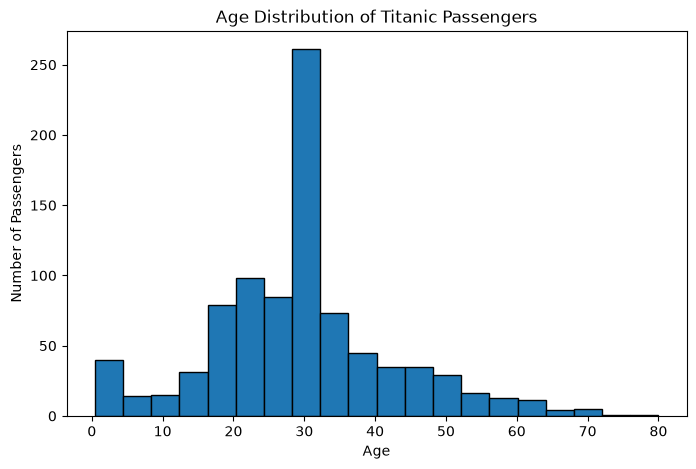

In [43]:
plt.figure(figsize=(8,5))

plt.hist(df['Age'], bins=20, edgecolor='black')

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

In [45]:
import seaborn as sns

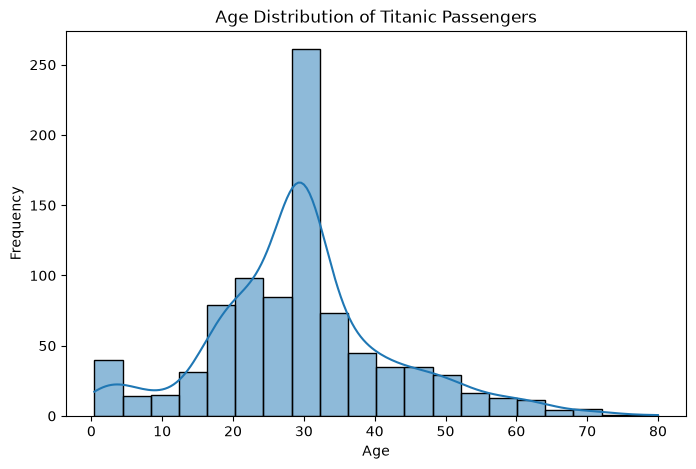

In [46]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Age', bins=20, kde=True)

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

In [47]:
df.to_csv("titanic_cleaned.csv", index=False)

In [48]:
import os

print(os.path.exists("titanic_cleaned.csv"))

True


In [49]:
cleaned_df = pd.read_csv("titanic_cleaned.csv")

cleaned_df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Sex_encoded,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,S,1,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C,0,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,S,0,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,S,0,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,S,1,0.0,0.0,1.0
5,6,0,3,"Moran, Mr. James",male,29.699118,0,0,330877,8.4583,Q,1,0.0,1.0,0.0
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.000000,0,0,17463,51.8625,S,1,0.0,0.0,1.0
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.000000,3,1,349909,21.0750,S,1,0.0,0.0,1.0
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.000000,0,2,347742,11.1333,S,0,0.0,0.0,1.0
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.000000,1,0,237736,30.0708,C,0,1.0,0.0,0.0


In [50]:
df.to_csv("titanic_cleaned.csv", index=False)

In [51]:
import os

print(os.path.exists("titanic_cleaned.csv"))
print("Dataset shape:", df.shape)

True
Dataset shape: (891, 15)


In [52]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'My Music', 'My Pictures', 'My Videos', 'Titanic.ipynb', 'titanic_cleaned.csv']


In [53]:
import os

print(os.path.abspath("Titanic.ipynb"))

C:\Users\smaha\Documents\Titanic.ipynb


In [54]:
import shutil, os

# Find where Desktop is
desktop = r"C:\Users\smaha\Desktop"
if not os.path.exists(desktop):
    desktop = r"C:\Users\smaha\OneDrive\Desktop"

print("Desktop is:", desktop)

shutil.copy("Titanic.ipynb", desktop)
shutil.copy("titanic_cleaned.csv", desktop)
print("Copied!")

Desktop is: C:\Users\smaha\OneDrive\Desktop
Copied!


In [ ]:
import os
os.startfile(os.getcwd())